<a href="https://colab.research.google.com/github/machindie/Analisis-Peramalan-ARIMA/blob/main/ARIMAAA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import boxcox
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera

In [ ]:
df = pd.read_excel('data berita.xlsx')

In [ ]:
print(df.dtypes)

Bulan     datetime64[ns]
Jumlah             int64
dtype: object


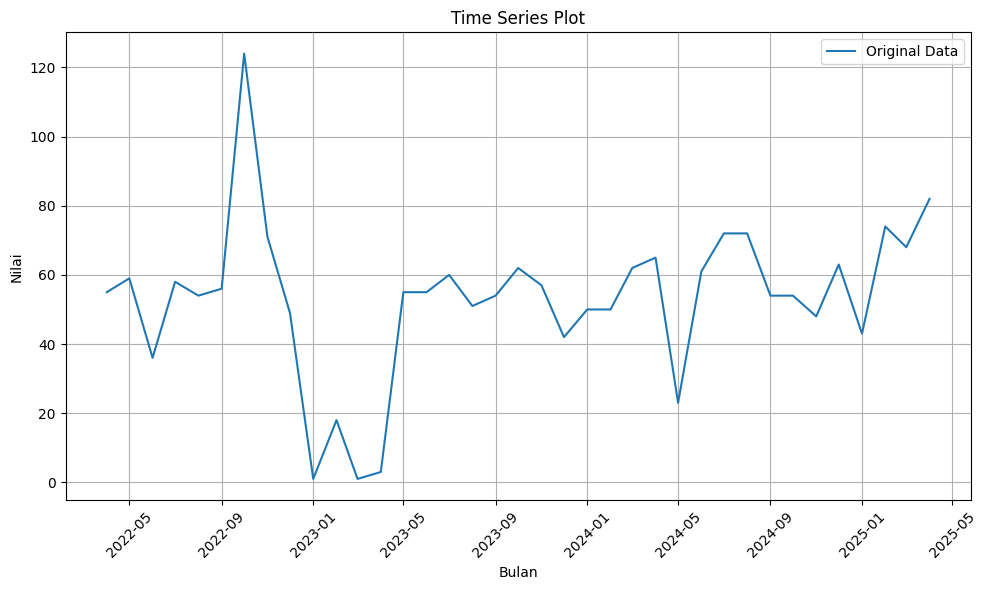

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(df['Bulan'], df['Jumlah'], label='Original Data')
plt.title("Time Series Plot")
plt.xlabel("Bulan")
plt.ylabel("Nilai")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
# Convert kolom 'Bulan' jadi datetime
df['Bulan'] = pd.to_datetime(df['Bulan'])

# Set kolom 'Bulan' sebagai index
df.set_index('Bulan', inplace=True)

# Cek index sekarang
print(df.index)

DatetimeIndex(['2022-04-01', '2022-05-01', '2022-06-01', '2022-07-01',
               '2022-08-01', '2022-09-01', '2022-10-01', '2022-11-01',
               '2022-12-01', '2023-01-01', '2023-02-01', '2023-03-01',
               '2023-04-01', '2023-05-01', '2023-06-01', '2023-07-01',
               '2023-08-01', '2023-09-01', '2023-10-01', '2023-11-01',
               '2023-12-01', '2024-01-01', '2024-02-01', '2024-03-01',
               '2024-04-01', '2024-05-01', '2024-06-01', '2024-07-01',
               '2024-08-01', '2024-09-01', '2024-10-01', '2024-11-01',
               '2024-12-01', '2025-01-01', '2025-02-01', '2025-03-01',
               '2025-04-01'],
              dtype='datetime64[ns]', name='Bulan', freq=None)


In [ ]:
# Pastikan index datetime
df.index = pd.to_datetime(df.index)

# Hitung titik potong data (80%)
train_size = int(len(df) * 0.8)

# Bagi data secara proporsional berdasarkan index posisi
train = df['Jumlah'].iloc[:train_size]
test = df['Jumlah'].iloc[train_size:]

print(f"Jumlah data training: {len(train)}")
print(f"Jumlah data testing: {len(test)}")
print(f"Training dari {train.index[0].date()} sampai {train.index[-1].date()}")
print(f"Testing dari {test.index[0].date()} sampai {test.index[-1].date()}")

Jumlah data training: 29
Jumlah data testing: 8
Training dari 2022-04-01 sampai 2024-08-01
Testing dari 2024-09-01 sampai 2025-04-01


In [ ]:
test

,Jumlah
Bulan,
2024-09-01,54
2024-10-01,54
2024-11-01,48
2024-12-01,63
2025-01-01,43
2025-02-01,74
2025-03-01,68
2025-04-01,82


In [ ]:
adf_result = adfuller(train)  # train adalah data training yang sudah kamu pisah
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

ADF Statistic: -3.080354398548642
p-value: 0.028041626577808933


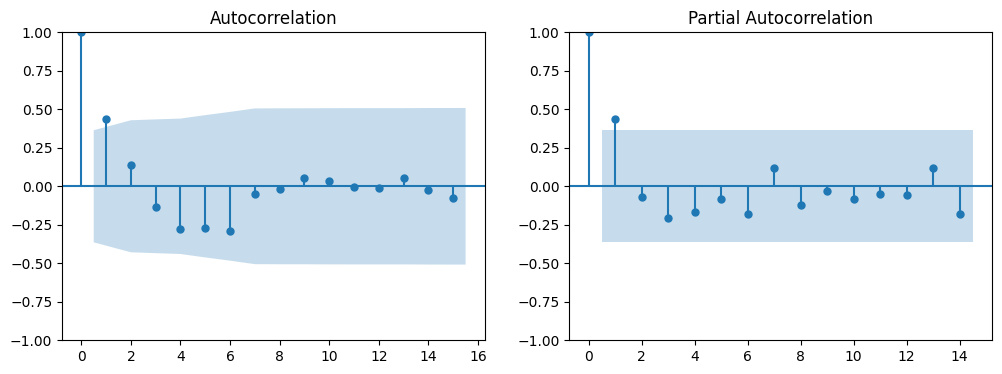

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(train.dropna(), ax=ax[0], lags=15)
plot_pacf(train.dropna(), ax=ax[1], lags=14)
plt.show()

In [ ]:
# --- 4. Fit model ARIMA(2,0,1) ke data latih ---
model = ARIMA(train, order=(2, 0, 1))
fit = model.fit()
print("\n=== Ringkasan Model ARIMA(2,0,1) ===")
print(fit.summary())

# --- 5. Uji Residual: Normalitas & Autokorelasi ---
resid = fit.resid

# Jarque-Bera test (normalitas)
jb_stat, jb_pval, _, _ = jarque_bera(resid)
print("\n=== Uji Jarque-Bera ===")
print(f"JB Statistic: {jb_stat:.4f}")
print(f"p-value: {jb_pval:.4f}")

# Ljung-Box test (autokorelasi hingga lag 10)
ljung = acorr_ljungbox(resid, lags=[10], return_df=True)
print("\n=== Uji Ljung-Box (lag 10) ===")
print(ljung)

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Us


=== Ringkasan Model ARIMA(2,0,1) ===
                               SARIMAX Results                                
Dep. Variable:                 Jumlah   No. Observations:                   29
Model:                 ARIMA(2, 0, 1)   Log Likelihood                -128.476
Date:                Wed, 11 Jun 2025   AIC                            266.953
Time:                        14:06:44   BIC                            273.789
Sample:                    04-01-2022   HQIC                           269.094
                         - 08-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         49.0464      3.282     14.946      0.000      42.615      55.478
ar.L1          1.3168      0.201      6.559      0.000       0.923       1.710
ar.L2         

In [ ]:
# --- 4. Fit model ARIMA(1,0,1) ke data latih ---
model = ARIMA(train, order=(1, 0, 1))
fit = model.fit()
print("\n=== Ringkasan Model ARIMA(1,0,1) ===")
print(fit.summary())

# --- 5. Uji Residual: Normalitas & Autokorelasi ---
resid = fit.resid

# Jarque-Bera test (normalitas)
jb_stat, jb_pval, _, _ = jarque_bera(resid)
print("\n=== Uji Jarque-Bera ===")
print(f"JB Statistic: {jb_stat:.4f}")
print(f"p-value: {jb_pval:.4f}")

# Ljung-Box test (autokorelasi hingga lag 10)
ljung = acorr_ljungbox(resid, lags=[10], return_df=True)
print("\n=== Uji Ljung-Box (lag 10) ===")
print(ljung)


=== Ringkasan Model ARIMA(1,0,1) ===
                               SARIMAX Results                                
Dep. Variable:                 Jumlah   No. Observations:                   29
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -130.392
Date:                Wed, 11 Jun 2025   AIC                            268.785
Time:                        14:06:47   BIC                            274.254
Sample:                    04-01-2022   HQIC                           270.498
                         - 08-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         51.4505      7.548      6.816      0.000      36.656      66.245
ar.L1          0.3797      0.439      0.864      0.388      -0.482       1.241
ma.L1         

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [ ]:
# --- 4. Fit model ARIMA(1,0,0) ke data latih ---
model = ARIMA(train, order=(1, 0, 0))
fit = model.fit()
print("\n=== Ringkasan Model ARIMA(1,0,0) ===")
print(fit.summary())

# --- 5. Uji Residual: Normalitas & Autokorelasi ---
resid = fit.resid

# Jarque-Bera test (normalitas)
jb_stat, jb_pval, _, _ = jarque_bera(resid)
print("\n=== Uji Jarque-Bera ===")
print(f"JB Statistic: {jb_stat:.4f}")
print(f"p-value: {jb_pval:.4f}")

# Ljung-Box test (autokorelasi hingga lag 10)
ljung = acorr_ljungbox(resid, lags=[10], return_df=True)
print("\n=== Uji Ljung-Box (lag 10) ===")
print(ljung)


=== Ringkasan Model ARIMA(1,0,0) ===
                               SARIMAX Results                                
Dep. Variable:                 Jumlah   No. Observations:                   29
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -130.420
Date:                Wed, 11 Jun 2025   AIC                            266.840
Time:                        14:06:51   BIC                            270.942
Sample:                    04-01-2022   HQIC                           268.124
                         - 08-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         51.5382      7.744      6.655      0.000      36.360      66.716
ar.L1          0.4375      0.193      2.266      0.023       0.059       0.816
sigma2       4

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [ ]:
# --- 4. Fit model ARIMA(2,0,0) ke data latih ---
model = ARIMA(train, order=(2, 0, 0))
fit = model.fit()
print("\n=== Ringkasan Model ARIMA(2,0,0) ===")
print(fit.summary())

# --- 5. Uji Residual: Normalitas & Autokorelasi ---
resid = fit.resid

# Jarque-Bera test (normalitas)
jb_stat, jb_pval, _, _ = jarque_bera(resid)
print("\n=== Uji Jarque-Bera ===")
print(f"JB Statistic: {jb_stat:.4f}")
print(f"p-value: {jb_pval:.4f}")

# Ljung-Box test (autokorelasi hingga lag 10)
ljung = acorr_ljungbox(resid, lags=[10], return_df=True)
print("\n=== Uji Ljung-Box (lag 10) ===")
print(ljung)


=== Ringkasan Model ARIMA(2,0,0) ===
                               SARIMAX Results                                
Dep. Variable:                 Jumlah   No. Observations:                   29
Model:                 ARIMA(2, 0, 0)   Log Likelihood                -130.368
Date:                Wed, 11 Jun 2025   AIC                            268.736
Time:                        14:07:35   BIC                            274.205
Sample:                    04-01-2022   HQIC                           270.449
                         - 08-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         51.3676      7.368      6.971      0.000      36.926      65.809
ar.L1          0.4633      0.262      1.766      0.077      -0.051       0.977
ar.L2         

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [ ]:
# --- 4. Fit model ARIMA(0,0,1) ke data latih ---
model = ARIMA(train, order=(0, 0, 1))
fit = model.fit()
print("\n=== Ringkasan Model ARIMA(0,0,1) ===")
print(fit.summary())

# --- 5. Uji Residual: Normalitas & Autokorelasi ---
resid = fit.resid

# Jarque-Bera test (normalitas)
jb_stat, jb_pval, _, _ = jarque_bera(resid)
print("\n=== Uji Jarque-Bera ===")
print(f"JB Statistic: {jb_stat:.4f}")
print(f"p-value: {jb_pval:.4f}")

# Ljung-Box test (autokorelasi hingga lag 10)
ljung = acorr_ljungbox(resid, lags=[10], return_df=True)
print("\n=== Uji Ljung-Box (lag 10) ===")
print(ljung)


=== Ringkasan Model ARIMA(0,0,1) ===
                               SARIMAX Results                                
Dep. Variable:                 Jumlah   No. Observations:                   29
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -130.876
Date:                Wed, 11 Jun 2025   AIC                            267.752
Time:                        14:07:39   BIC                            271.854
Sample:                    04-01-2022   HQIC                           269.037
                         - 08-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         51.0908      5.738      8.903      0.000      39.844      62.338
ma.L1          0.3842      0.221      1.736      0.083      -0.050       0.818
sigma2       4

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [ ]:
std_resid = resid.std()
threshold = 3 * std_resid
outlier_idx = resid[np.abs(resid) > threshold].index
print(f"Outlier terdeteksi di index: {outlier_idx.tolist()}")

Outlier terdeteksi di index: [Timestamp('2022-10-01 00:00:00')]


In [ ]:
outlier_idx

DatetimeIndex(['2022-10-01'], dtype='datetime64[ns]', name='Bulan', freq=None)

In [ ]:
dummies_train = pd.DataFrame(0, index=train.index, columns=[f'AO_{i}' for i in outlier_idx])
for i in outlier_idx:
    dummies_train.loc[i, f'AO_{i}'] = 1

print(dummies_train)

            AO_2022-10-01 00:00:00
Bulan                             
2022-04-01                       0
2022-05-01                       0
2022-06-01                       0
2022-07-01                       0
2022-08-01                       0
2022-09-01                       0
2022-10-01                       1
2022-11-01                       0
2022-12-01                       0
2023-01-01                       0
2023-02-01                       0
2023-03-01                       0
2023-04-01                       0
2023-05-01                       0
2023-06-01                       0
2023-07-01                       0
2023-08-01                       0
2023-09-01                       0
2023-10-01                       0
2023-11-01                       0
2023-12-01                       0
2024-01-01                       0
2024-02-01                       0
2024-03-01                       0
2024-04-01                       0
2024-05-01                       0
2024-06-01          

In [ ]:
model_ao = ARIMA(train, order=(1, 0, 0), exog=dummies_train)
fit_ao = model_ao.fit()
print("\n=== Model setelah penanganan AO ===")
print(fit_ao.summary())

resid_ao = fit_ao.resid
jb_stat, jb_pval, _, _ = jarque_bera(resid_ao)
print(f"\nJB test p-value setelah AO: {jb_pval:.4f}")

ljung = acorr_ljungbox(resid_ao, lags=[10], return_df=True)
print(f"Ljung-Box p-value setelah AO: {ljung['lb_pvalue'].values[0]:.4f}")


=== Model setelah penanganan AO ===
                               SARIMAX Results                                
Dep. Variable:                 Jumlah   No. Observations:                   29
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -123.905
Date:                Wed, 11 Jun 2025   AIC                            255.811
Time:                        14:07:54   BIC                            261.280
Sample:                    04-01-2022   HQIC                           257.523
                         - 08-01-2024                                         
Covariance Type:                  opg                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     49.6606      9.832      5.051      0.000      30.390      68.932
AO_2022-10-01 00:00:00    63.2863     27.143      2.332   

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [ ]:
# --- Dummy AO untuk test: kolom sama, semua 0 ---
dummies_test = pd.DataFrame(0, index=test.index, columns=dummies_train.columns)

# --- Prediksi in-sample dan out-of-sample ---
pred_train = fit_ao.predict(start=train.index[0], end=train.index[-1], exog=dummies_train)
pred_test = fit_ao.predict(start=test.index[0], end=test.index[-1], exog=dummies_test)

In [ ]:
pred_train

,predicted_mean
2022-04-01,49.660631
2022-05-01,52.324737
2022-06-01,54.320558
2022-07-01,42.844587
2022-08-01,53.821603
2022-09-01,51.825782
2022-10-01,116.110035
2022-11-01,55.175597
2022-12-01,60.308022
2023-01-01,49.331006


In [ ]:
pred_test

,predicted_mean
2024-09-01,60.806977
2024-10-01,55.222159
2024-11-01,52.435585
2024-12-01,51.045209
2025-01-01,50.351474
2025-02-01,50.005331
2025-03-01,49.832621
2025-04-01,49.746446


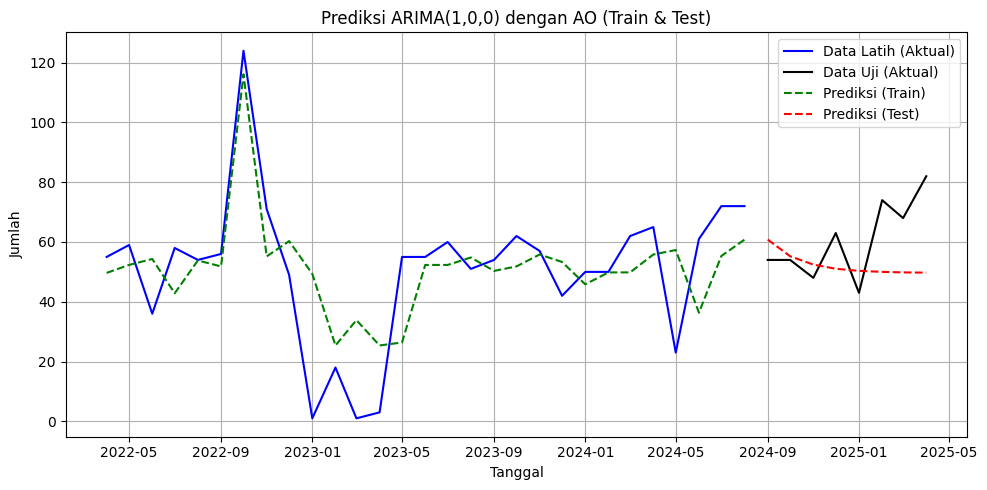

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(train, label='Data Latih (Aktual)', color='blue')
plt.plot(test, label='Data Uji (Aktual)', color='black')
plt.plot(pred_train, label='Prediksi (Train)', linestyle='--', color='green')
plt.plot(pred_test, label='Prediksi (Test)', linestyle='--', color='red')
plt.title("Prediksi ARIMA(1,0,0) dengan AO (Train & Test)")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# --- Dummy AO untuk test: kolom sama, semua 0 ---
dummies_test = pd.DataFrame(0, index=test.index, columns=dummies_train.columns)

# --- Prediksi out-of-sample ---
pred_test = fit_ao.predict(start=test.index[0], end=test.index[-1], exog=dummies_test)

In [ ]:
pred_test

,predicted_mean
2024-09-01,60.806977
2024-10-01,55.222159
2024-11-01,52.435585
2024-12-01,51.045209
2025-01-01,50.351474
2025-02-01,50.005331
2025-03-01,49.832621
2025-04-01,49.746446


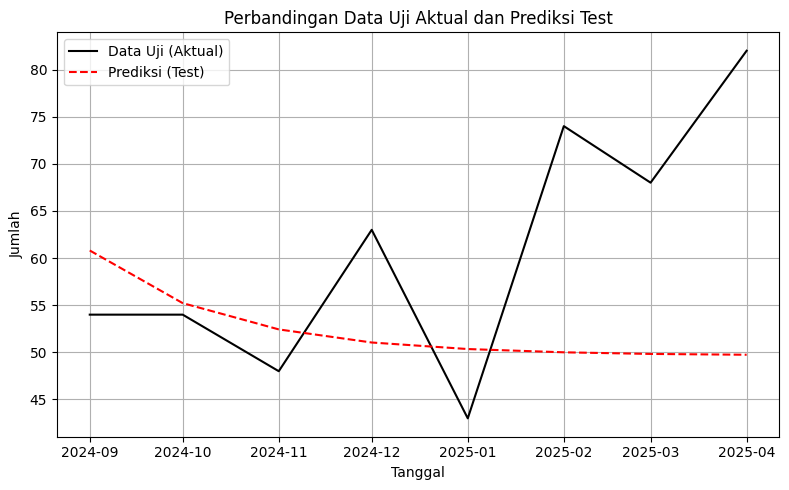

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(test, label='Data Uji (Aktual)', color='black')
plt.plot(pred_test, label='Prediksi (Test)', linestyle='--', color='red')
plt.title("Perbandingan Data Uji Aktual dan Prediksi Test")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

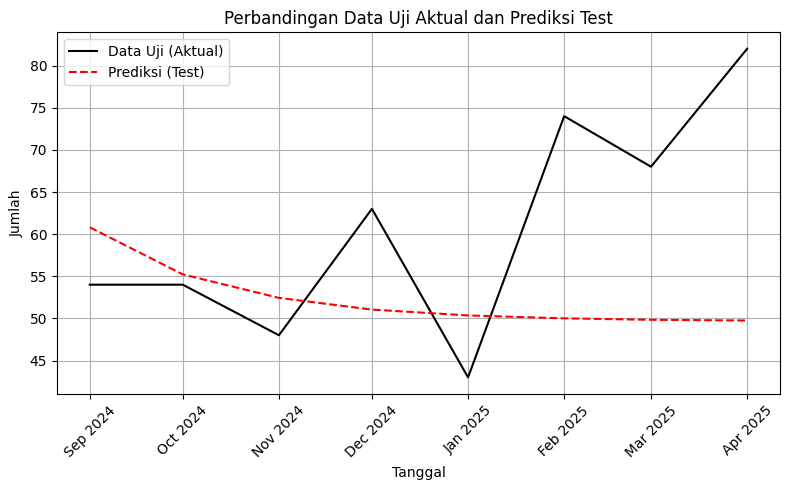

In [ ]:
import matplotlib.dates as mdates

plt.figure(figsize=(8, 5))
plt.plot(test, label='Data Uji (Aktual)', color='black')
plt.plot(pred_test, label='Prediksi (Test)', linestyle='--', color='red')

plt.title("Perbandingan Data Uji Aktual dan Prediksi Test")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah")
plt.legend()
plt.grid(True)

# Format sumbu X agar tampil per bulan
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))  # Format: Jan 2025
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())  # Tampilkan setiap bulan
plt.xticks(rotation=45)  # Putar label agar tidak tumpang tindih

plt.tight_layout()
plt.show()

In [ ]:
# Model ARIMA(1,0,0) tanpa AO
model_no_ao = ARIMA(train, order=(1, 0, 0))
fit_no_ao = model_no_ao.fit()

# Prediksi data test tanpa AO
pred_test_no_ao = fit_no_ao.predict(start=test.index[0], end=test.index[-1])

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [ ]:
pred_test_no_ao

,predicted_mean
2024-09-01,60.490456
2024-10-01,55.454902
2024-11-01,53.251791
2024-12-01,52.287906
2025-01-01,51.866195
2025-02-01,51.681692
2025-03-01,51.600970
2025-04-01,51.565653


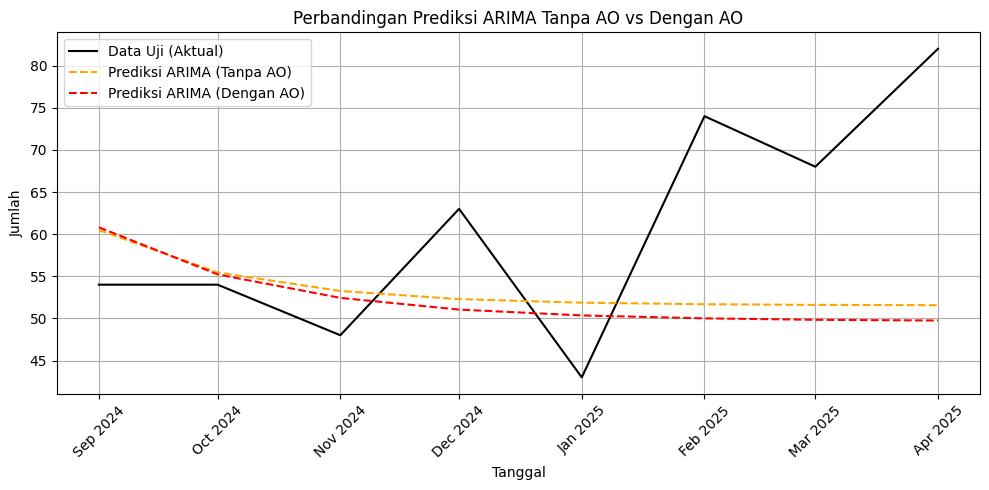

In [ ]:
import matplotlib.dates as mdates
plt.figure(figsize=(10, 5))

plt.plot(test, label='Data Uji (Aktual)', color='black')
plt.plot(pred_test_no_ao, label='Prediksi ARIMA (Tanpa AO)', linestyle='--', color='orange')
plt.plot(pred_test, label='Prediksi ARIMA (Dengan AO)', linestyle='--', color='red')

plt.title("Perbandingan Prediksi ARIMA Tanpa AO vs Dengan AO")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah")
plt.legend()
plt.grid(True)

# Format sumbu X per bulan
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(test, pred_test)
rmse = np.sqrt(mean_squared_error(test, pred_test))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 13.2733
RMSE: 16.6229


In [ ]:
 from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test, pred_test)
rmse = np.sqrt(mean_squared_error(test, pred_test))
mape = np.mean(np.abs((test - pred_test) / test)) * 100

print(f"MAE : {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")

MAE : 13.2733
RMSE: 16.6229
MAPE: 19.83%


In [ ]:
# --- Hitung Error dan MAPE ---
errors = test - pred_test
mape = np.mean(np.abs(errors / test)) * 100
print(f"\nMAPE pada data uji: {mape:.2f}%")


MAPE pada data uji: 19.83%


In [ ]:
mape

np.float64(19.832180709016868)

In [ ]:
errors

,0
Bulan,
2024-09-01,-6.806977
2024-10-01,-1.222159
2024-11-01,-4.435585
2024-12-01,11.954791
2025-01-01,-7.351474
2025-02-01,23.994669
2025-03-01,18.167379
2025-04-01,32.253554


In [ ]:
# Buat Tabel Error Per Data Uji
error_df = pd.DataFrame({
    'Aktual': test,
    'Prediksi': pred_test,
    'Error': errors,
    'APE (%)': np.abs(errors / test) * 100
})
print("\n=== Tabel Error Per Data Uji ===")
print(error_df)


=== Tabel Error Per Data Uji ===
            Aktual   Prediksi      Error    APE (%)
2024-09-01      54  60.806977  -6.806977  12.605513
2024-10-01      54  55.222159  -1.222159   2.263257
2024-11-01      48  52.435585  -4.435585   9.240802
2024-12-01      63  51.045209  11.954791  18.975859
2025-01-01      43  50.351474  -7.351474  17.096450
2025-02-01      74  50.005331  23.994669  32.425229
2025-03-01      68  49.832621  18.167379  26.716734
2025-04-01      82  49.746446  32.253554  39.333602


In [ ]:
import pandas as pd

# Jumlah periode masa depan yang ingin diramalkan
n_forecast = 12

# Buat index tanggal masa depan
future_start = test.index[-1] + pd.offsets.MonthBegin(1)
future_index = pd.date_range(start=future_start, periods=n_forecast, freq='MS')

# Buat dummy exog untuk data uji
dummies_test = pd.DataFrame(0, index=test.index, columns=dummies_train.columns)

# Buat dummy exog untuk data masa depan
dummies_future = pd.DataFrame(0, index=future_index, columns=dummies_train.columns)

# Gabungkan exog data uji dan masa depan (harus sesuai jumlah out-of-sample)
exog_full = pd.concat([dummies_test, dummies_future])

# Lakukan peramalan masa depan
future_forecast = fit_ao.predict(
    start=exog_full.index[0],
    end=exog_full.index[-1],
    exog=exog_full
)

# Ambil hasil peramalan khusus masa depan
future_forecast = future_forecast.loc[future_index]

# Buat DataFrame hasil peramalan masa depan
forecast_df = pd.DataFrame({
    'Periode': future_forecast.index,
    'Forecast': future_forecast.values
})

print("\n=== Hasil Peramalan Masa Depan ===")
print(forecast_df)



=== Hasil Peramalan Masa Depan ===
      Periode   Forecast
0  2025-05-01  49.703449
1  2025-06-01  49.681995
2  2025-07-01  49.671291
3  2025-08-01  49.665950
4  2025-09-01  49.663285
5  2025-10-01  49.661955
6  2025-11-01  49.661292
7  2025-12-01  49.660961
8  2026-01-01  49.660796
9  2026-02-01  49.660713
10 2026-03-01  49.660672
11 2026-04-01  49.660652


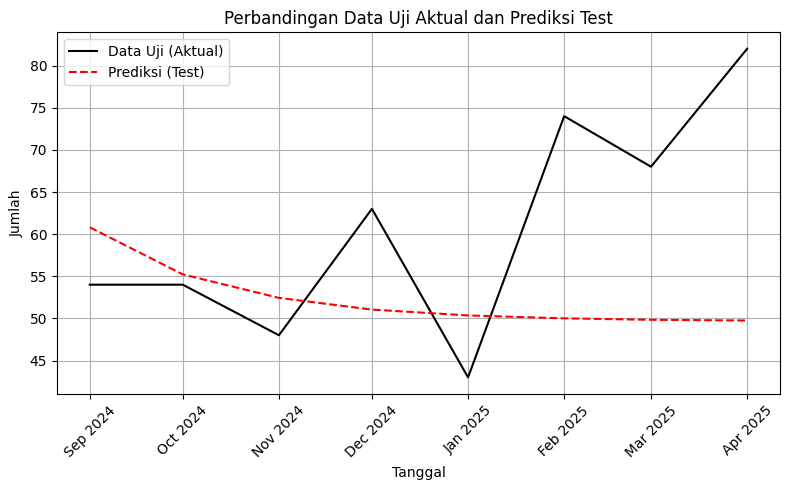

ValueError: Provided exogenous values are not of the appropriate shape. Required (14, 1), got (6, 1).

In [ ]:
# --- Plot Prediksi vs Aktual ---
plt.figure(figsize=(8, 5))
plt.plot(test, label='Data Uji (Aktual)', color='black')
plt.plot(pred_test, label='Prediksi (Test)', linestyle='--', color='red')
plt.title("Perbandingan Data Uji Aktual dan Prediksi Test")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah")
plt.legend()
plt.grid(True)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Peramalan Masa Depan ---
future_steps = 6  # Misalnya ramal 6 bulan ke depan
last_index = df.index[-1]
future_index = pd.date_range(start=last_index + pd.offsets.MonthBegin(), periods=future_steps, freq='MS')

# Dummy AO untuk future (semua nol)
dummies_future = pd.DataFrame(0, index=future_index, columns=dummies_train.columns)

forecast = fit_ao.predict(start=future_index[0], end=future_index[-1], exog=dummies_future)

print("\n=== Hasil Peramalan Masa Depan ===")
forecast_df = pd.DataFrame({'Peramalan': forecast})
print(forecast_df)

# Plot Forecast
plt.figure(figsize=(8, 5))
plt.plot(df['Jumlah'], label='Data Aktual', color='blue')
plt.plot(forecast, label='Peramalan (Forecast)', linestyle='--', color='green')
plt.title("Peramalan Masa Depan")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah")
plt.legend()
plt.grid(True)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()